# Fase 4 — Extração de Insights e Feature Importance

**Projeto:** Redes Sociais vs Produtividade — Aprendizado de Máquina via Random Forest

Objetivos deste notebook:

1. Abrir a "caixa-preta" do Random Forest: **quais variáveis o modelo realmente usa** para prever a produtividade?
2. Comparar dois métodos de *Feature Importance* (**MDI** e **Permutação**) e entender por que eles discordam.
3. Medir o efeito de cada variável na previsão com **Dependência Parcial** e simulações "e se?".
4. Escrever uma análise profunda sobre o que o algoritmo descobriu a respeito do impacto das redes sociais na produtividade.

## 1. Configuração do ambiente

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.metrics import r2_score

RANDOM_STATE = 42
DATA_DIR = Path("data")
MODEL_DIR = Path("models")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

SURFACE, INK, INK_2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b2"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "legend.frameon": False,
})


def salvar(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")


# Nomes amigáveis para os gráficos (também usados nos slides)
NOMES = {
    "job_satisfaction_score": "Satisfação com o trabalho",
    "daily_social_media_time": "Horas/dia em redes sociais",
    "number_of_notifications": "Notificações por dia",
    "screen_time_before_sleep": "Tela antes de dormir",
    "weekly_offline_hours": "Horas offline por semana",
    "sleep_hours": "Horas de sono",
    "stress_level": "Nível de estresse",
    "days_feeling_burnout_per_month": "Dias de burnout no mês",
    "work_hours_per_day": "Horas de trabalho/dia",
    "breaks_during_work": "Pausas no trabalho",
    "coffee_consumption_per_day": "Cafés por dia",
    "age": "Idade",
    "uses_focus_apps": "Usa apps de foco",
    "has_digital_wellbeing_enabled": "Bem-estar digital ativo",
}


def nome(col):
    if col in NOMES:
        return NOMES[col]
    prefixo, _, valor = col.partition("_")
    return {"gender": "Gênero", "job": "Área", "platform": "Rede"}.get(prefixo, prefixo) + f": {valor}"

## 2. Carregamento do modelo e dos dados

In [2]:
metadados = json.loads((MODEL_DIR / "metadata.json").read_text())
ALVO, FEATURES = metadados["alvo"], metadados["features"]

modelo = joblib.load(MODEL_DIR / "random_forest.joblib")
treino = pd.read_csv(DATA_DIR / "train.csv")
teste = pd.read_csv(DATA_DIR / "test.csv")
# Convertidos para float: a dependência parcial do scikit-learn não aceita colunas inteiras
X_train, y_train = treino[FEATURES].astype(float), treino[ALVO]
X_test, y_test = teste[FEATURES].astype(float), teste[ALVO]
print(f"R² do modelo no teste: {r2_score(y_test, modelo.predict(X_test)):.3f}")

R² do modelo no teste: 0.716


## 3. Importância por impureza (MDI)

É a *Feature Importance* "nativa" do Random Forest (`modelo.feature_importances_`). Cada vez que uma árvore divide os dados usando uma variável, o erro (a *impureza*) diminui. O MDI (*Mean Decrease in Impurity*) soma essas reduções para cada variável, tira a média entre as 300 árvores e normaliza o total para 100%.

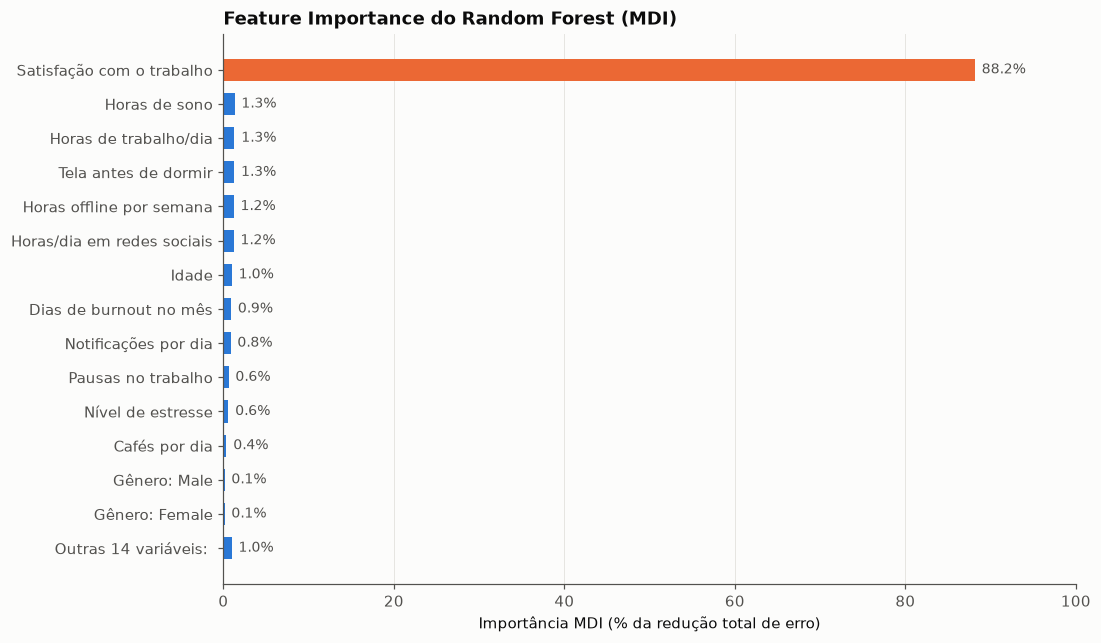

Satisfação com o trabalho: 88.2%
Todas as outras 27 variáveis somadas: 11.8%


In [3]:
mdi = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values(ascending=False)

top = mdi.head(14)
outras = mdi.iloc[14:].sum()
plot = pd.concat([top, pd.Series({f"Outras {len(mdi) - 14} variáveis": outras})])[::-1]

fig, ax = plt.subplots(figsize=(10, 6.5))
cores = [ORANGE if c == "job_satisfaction_score" else BLUE for c in plot.index]
ax.barh([nome(c) for c in plot.index], plot.values * 100, color=cores, height=0.65)
for i, v in enumerate(plot.values * 100):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, 100)
ax.set_xlabel("Importância MDI (% da redução total de erro)")
ax.set_title("Feature Importance do Random Forest (MDI)")
ax.grid(axis="y", visible=False)
salvar(fig, "04_feature_importance_mdi")
plt.show()

print(f"Satisfação com o trabalho: {mdi['job_satisfaction_score']:.1%}")
print(f"Todas as outras 27 variáveis somadas: {1 - mdi['job_satisfaction_score']:.1%}")

O MDI dá **~88%** da importância à satisfação com o trabalho. Mas sobra ~12% espalhado entre as demais variáveis, cada uma com cerca de 1%, incluindo o tempo em redes sociais. Isso significa que elas têm um efeito pequeno, porém real? A próxima seção mostra que **não**.

## 4. Importância por permutação

O método de **permutação** responde a uma pergunta mais direta: *"quanto o modelo piora se eu embaralhar esta variável?"*

1. Medimos o R² do modelo no **teste**.
2. Embaralhamos aleatoriamente uma coluna, destruindo a relação dela com o alvo, e medimos o R² de novo.
3. A queda do R² é a importância da variável. Repetimos 10 vezes para obter uma média e uma margem de variação.

Se embaralhar uma variável não muda nada, o modelo não depende dela para acertar.

In [4]:
perm = permutation_importance(modelo, X_test, y_test, n_repeats=10, scoring="r2",
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({
    "queda_r2": perm.importances_mean,
    "desvio": perm.importances_std,
}, index=FEATURES).sort_values("queda_r2", ascending=False)
perm_df.head(10).round(4)

,queda_r2,desvio
job_satisfaction_score,1.4397,0.0295
weekly_offline_hours,0.0004,0.0003
stress_level,0.0002,0.0002
coffee_consumption_per_day,0.0002,0.0001
number_of_notifications,0.0001,0.0001
job_Student,0.0001,0.0001
job_Education,0.0001,0.0001
sleep_hours,0.0001,0.0005
gender_Female,0.0000,0.0001
platform_Instagram,0.0000,0.0001


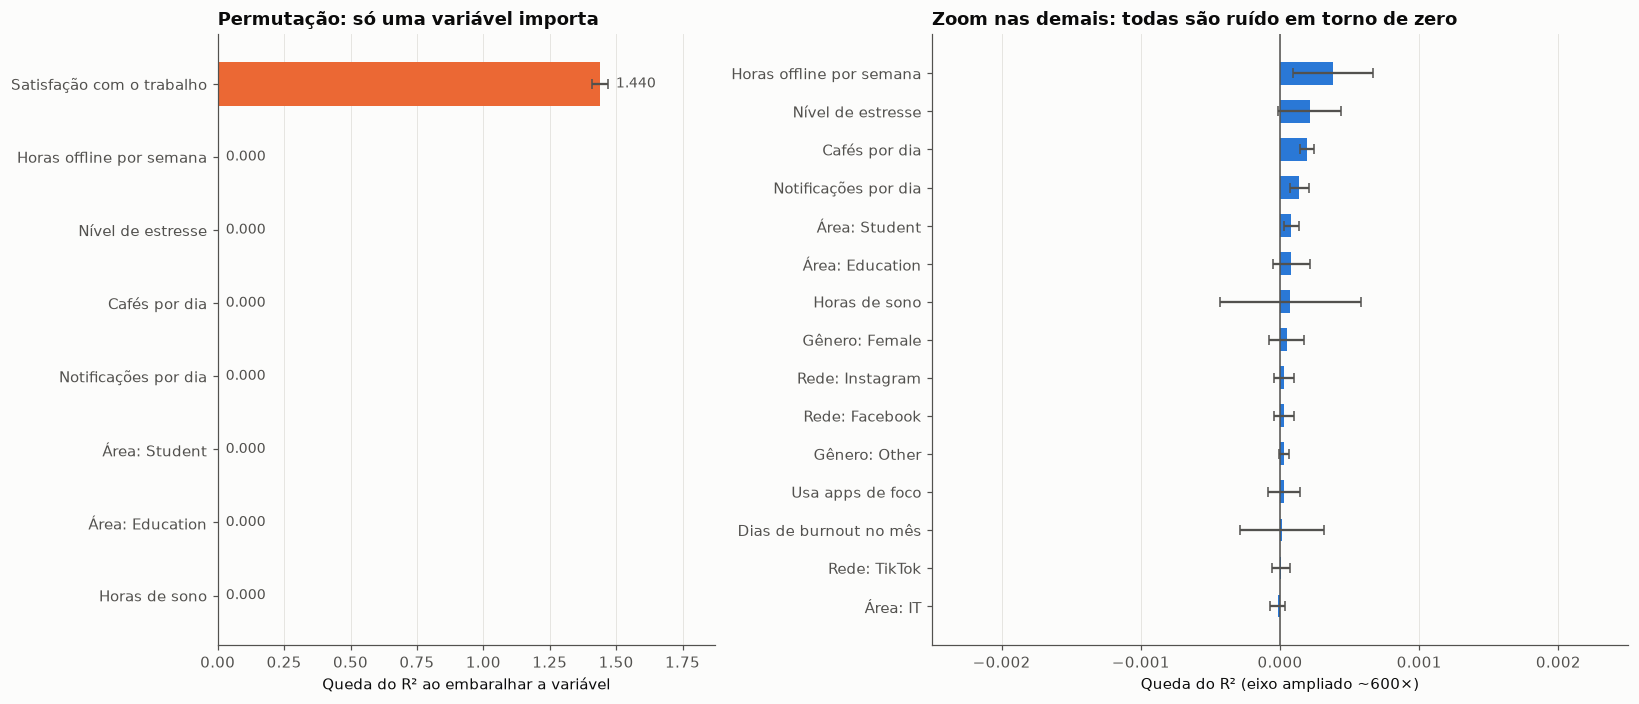

Satisfação: embaralhar derruba o R² em 1.440
Maior queda entre as outras 27: 0.0004 (Horas offline por semana)
Variáveis com importância negativa (embaralhar até MELHORA o modelo): 13


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.4]})

ax = axes[0]
d = perm_df.head(8)[::-1]
cores = [ORANGE if c == "job_satisfaction_score" else BLUE for c in d.index]
ax.barh([nome(c) for c in d.index], d["queda_r2"], xerr=d["desvio"], color=cores, height=0.6,
        error_kw={"ecolor": INK_2, "capsize": 3})
for i, (v, e) in enumerate(zip(d["queda_r2"], d["desvio"])):
    ax.text(v + e + 0.03, i, f"{v:.3f}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, d["queda_r2"].max() * 1.3)
ax.set_xlabel("Queda do R² ao embaralhar a variável")
ax.set_title("Permutação: só uma variável importa")
ax.grid(axis="y", visible=False)

ax = axes[1]
d = perm_df.drop(index="job_satisfaction_score").head(15)[::-1]
ax.barh([nome(c) for c in d.index], d["queda_r2"], xerr=d["desvio"], color=BLUE, height=0.6,
        error_kw={"ecolor": INK_2, "capsize": 3})
ax.axvline(0, color=INK_2, lw=1)
ax.set_xlim(-0.0025, 0.0025)
ax.set_xlabel("Queda do R² (eixo ampliado ~600×)")
ax.set_title("Zoom nas demais: todas são ruído em torno de zero")
ax.grid(axis="y", visible=False)

fig.tight_layout()
salvar(fig, "04_feature_importance_permutacao")
plt.show()

print(f"Satisfação: embaralhar derruba o R² em {perm_df.loc['job_satisfaction_score', 'queda_r2']:.3f}")
outras = perm_df.drop(index="job_satisfaction_score")
print(f"Maior queda entre as outras 27: {outras['queda_r2'].max():.4f} ({nome(outras['queda_r2'].idxmax())})")
print(f"Variáveis com importância negativa (embaralhar até MELHORA o modelo): {(outras['queda_r2'] < 0).sum()}")

**Leitura:** embaralhar a satisfação com o trabalho **destrói o modelo**: o R² despenca de ~0,72 para um valor negativo, pior do que chutar a média. Embaralhar qualquer outra variável, incluindo **todas as de redes sociais**, muda o R² em menos de 0,001, e várias até têm importância levemente *negativa*. O modelo não depende delas para acertar.

## 5. Por que MDI e permutação discordam? Um teste com ruído puro

O MDI é calculado **no treino** e premia qualquer divisão que reduza o erro, inclusive divisões que só se ajustam ao ruído. Variáveis contínuas, com muitos valores distintos, oferecem muitas posições de corte e acabam sendo usadas para "afinar" o ajuste nas folhas mais profundas. Esse viés é bem documentado na literatura.

**Experimento:** treinamos o mesmo Random Forest adicionando uma coluna `RUIDO_ALEATORIO`, com números sorteados ao acaso e sem nenhuma relação com nada. Se o MDI for confiável, essa coluna deve receber importância zero.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
X_train_ruido = X_train.assign(RUIDO_ALEATORIO=rng.normal(size=len(X_train)))
X_test_ruido = X_test.assign(RUIDO_ALEATORIO=rng.normal(size=len(X_test)))

modelo_ruido = RandomForestRegressor(**{**metadados["hiperparametros"], "n_jobs": -1}).fit(X_train_ruido, y_train)
mdi_ruido = pd.Series(modelo_ruido.feature_importances_, index=X_train_ruido.columns).sort_values(ascending=False)
perm_ruido = permutation_importance(modelo_ruido, X_test_ruido, y_test, n_repeats=10,
                                    random_state=RANDOM_STATE, n_jobs=-1)
perm_ruido = pd.Series(perm_ruido.importances_mean, index=X_test_ruido.columns)

foco = ["RUIDO_ALEATORIO", "daily_social_media_time", "number_of_notifications",
        "screen_time_before_sleep", "sleep_hours", "stress_level"]
experimento = pd.DataFrame({
    "MDI (%)": mdi_ruido[foco] * 100,
    "posição no ranking MDI": [int(mdi_ruido.index.get_loc(c)) + 1 for c in foco],
    "Permutação (queda do R²)": perm_ruido[foco],
})
experimento.index = ["RUÍDO ALEATÓRIO (sorteado)"] + [nome(c) for c in foco[1:]]
experimento.round(4)

,MDI (%),posição no ranking MDI,Permutação (queda do R²)
RUÍDO ALEATÓRIO (sorteado),1.2303,2,-0.0003
Horas/dia em redes sociais,1.1357,7,-0.0002
Notificações por dia,0.7932,10,-0.0001
Tela antes de dormir,1.1663,5,-0.0003
Horas de sono,1.2087,3,-0.0000
Nível de estresse,0.5338,12,0.0000


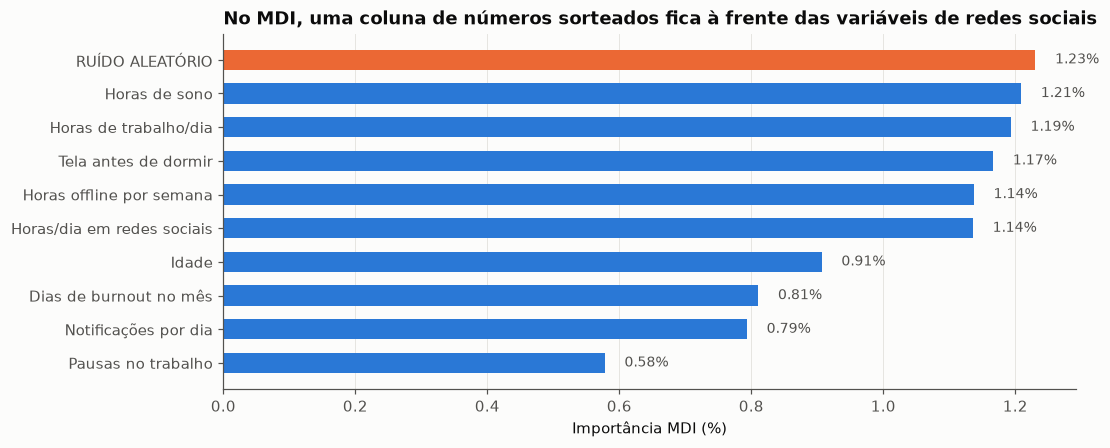

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
d = mdi_ruido.drop(index="job_satisfaction_score").head(10)[::-1] * 100
cores = [ORANGE if c == "RUIDO_ALEATORIO" else BLUE for c in d.index]
rotulos = ["RUÍDO ALEATÓRIO" if c == "RUIDO_ALEATORIO" else nome(c) for c in d.index]
ax.barh(rotulos, d.values, color=cores, height=0.6)
for i, v in enumerate(d.values):
    ax.text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9, color=INK_2)
ax.set_xlabel("Importância MDI (%)")
ax.set_title("No MDI, uma coluna de números sorteados fica à frente das variáveis de redes sociais")
ax.grid(axis="y", visible=False)
salvar(fig, "04_mdi_vs_ruido")
plt.show()

**Leitura:** uma coluna de **números sorteados ao acaso** fica em **2º lugar** no ranking MDI, à frente das horas em redes sociais, das notificações e da tela antes de dormir. Já a permutação dá ~0 para todas elas, exatamente o que se espera de ruído. Conclusão:

> Os ~12% que o MDI distribui entre as outras variáveis **não são sinal**: é o modelo ajustando ruído no treino. No ranking MDI, as variáveis de redes sociais são **indistinguíveis de números aleatórios**.

**Lição metodológica:** a *Feature Importance* nativa (MDI) é útil como primeira olhada, mas pode enganar. Para conclusões, use a **importância por permutação no conjunto de teste**.

## 6. Importância por tema

Somar importâncias individuais de variáveis one-hot (ex.: cinco colunas de rede social) não é o ideal. Aqui embaralhamos **grupos inteiros de variáveis ao mesmo tempo**, com a mesma permutação de linhas, para medir quanto cada *tema* contribui.

In [8]:
GRUPOS = {
    "Satisfação com o trabalho": ["job_satisfaction_score"],
    "Hábitos digitais (redes sociais)": [
        "daily_social_media_time", "number_of_notifications", "screen_time_before_sleep",
        "weekly_offline_hours", "uses_focus_apps", "has_digital_wellbeing_enabled",
    ] + [c for c in FEATURES if c.startswith("platform_")],
    "Bem-estar (sono, estresse, burnout)": ["sleep_hours", "stress_level", "days_feeling_burnout_per_month"],
    "Rotina de trabalho": ["work_hours_per_day", "breaks_during_work", "coffee_consumption_per_day"],
    "Perfil (idade, gênero, área)": ["age"] + [c for c in FEATURES if c.startswith(("gender_", "job_"))
                                              and c != "job_satisfaction_score"],
}
assert sorted(sum(GRUPOS.values(), [])) == sorted(FEATURES)

r2_base = r2_score(y_test, modelo.predict(X_test))
rng = np.random.default_rng(RANDOM_STATE)
linhas = []
for grupo, cols in GRUPOS.items():
    quedas = []
    for _ in range(10):
        X_perm = X_test.copy()
        X_perm[cols] = X_test[cols].to_numpy()[rng.permutation(len(X_test))]
        quedas.append(r2_base - r2_score(y_test, modelo.predict(X_perm)))
    linhas.append({"tema": grupo, "nº variáveis": len(cols), "queda_r2": np.mean(quedas), "desvio": np.std(quedas)})

temas = pd.DataFrame(linhas).set_index("tema").sort_values("queda_r2", ascending=False)
temas.round(4)

,nº variáveis,queda_r2,desvio
tema,,,
Satisfação com o trabalho,1,1.4307,0.0151
Hábitos digitais (redes sociais),11,0.0003,0.0006
"Bem-estar (sono, estresse, burnout)",3,0.0001,0.0005
"Perfil (idade, gênero, área)",10,0.0000,0.0003
Rotina de trabalho,3,-0.0004,0.0006


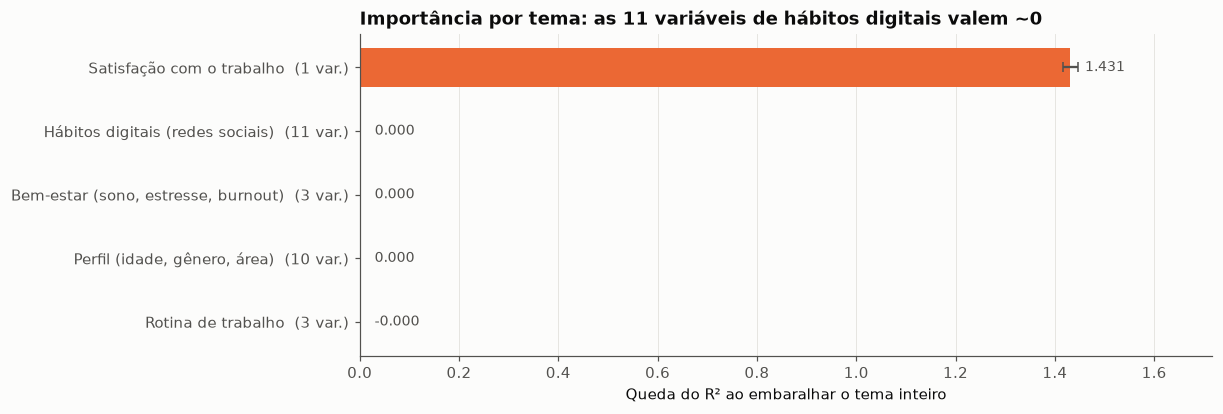

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
d = temas[::-1]
cores = [ORANGE if t == "Satisfação com o trabalho" else BLUE for t in d.index]
ax.barh([f"{t}  ({n} var.)" for t, n in zip(d.index, d["nº variáveis"])], d["queda_r2"], xerr=d["desvio"],
        color=cores, height=0.6, error_kw={"ecolor": INK_2, "capsize": 3})
for i, v in enumerate(d["queda_r2"]):
    ax.text(max(v, 0) + 0.03, i, f"{v:.3f}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, d["queda_r2"].max() * 1.2)
ax.set_xlabel("Queda do R² ao embaralhar o tema inteiro")
n_digitais = len(GRUPOS["Hábitos digitais (redes sociais)"])
ax.set_title(f"Importância por tema: as {n_digitais} variáveis de hábitos digitais valem ~0")
ax.grid(axis="y", visible=False)
salvar(fig, "04_importancia_por_tema")
plt.show()

## 7. Dependência parcial: como a previsão muda quando uma variável muda?

A importância diz **quanto** uma variável importa, mas não **em que direção**. O gráfico de **Dependência Parcial** responde a isso: para cada valor de uma variável, ele mede a previsão média do modelo considerando todas as pessoas do teste com aquele valor e mantendo as demais características de cada uma. Todos os painéis usam a **mesma escala (0 a 10)** para permitir comparar os efeitos.

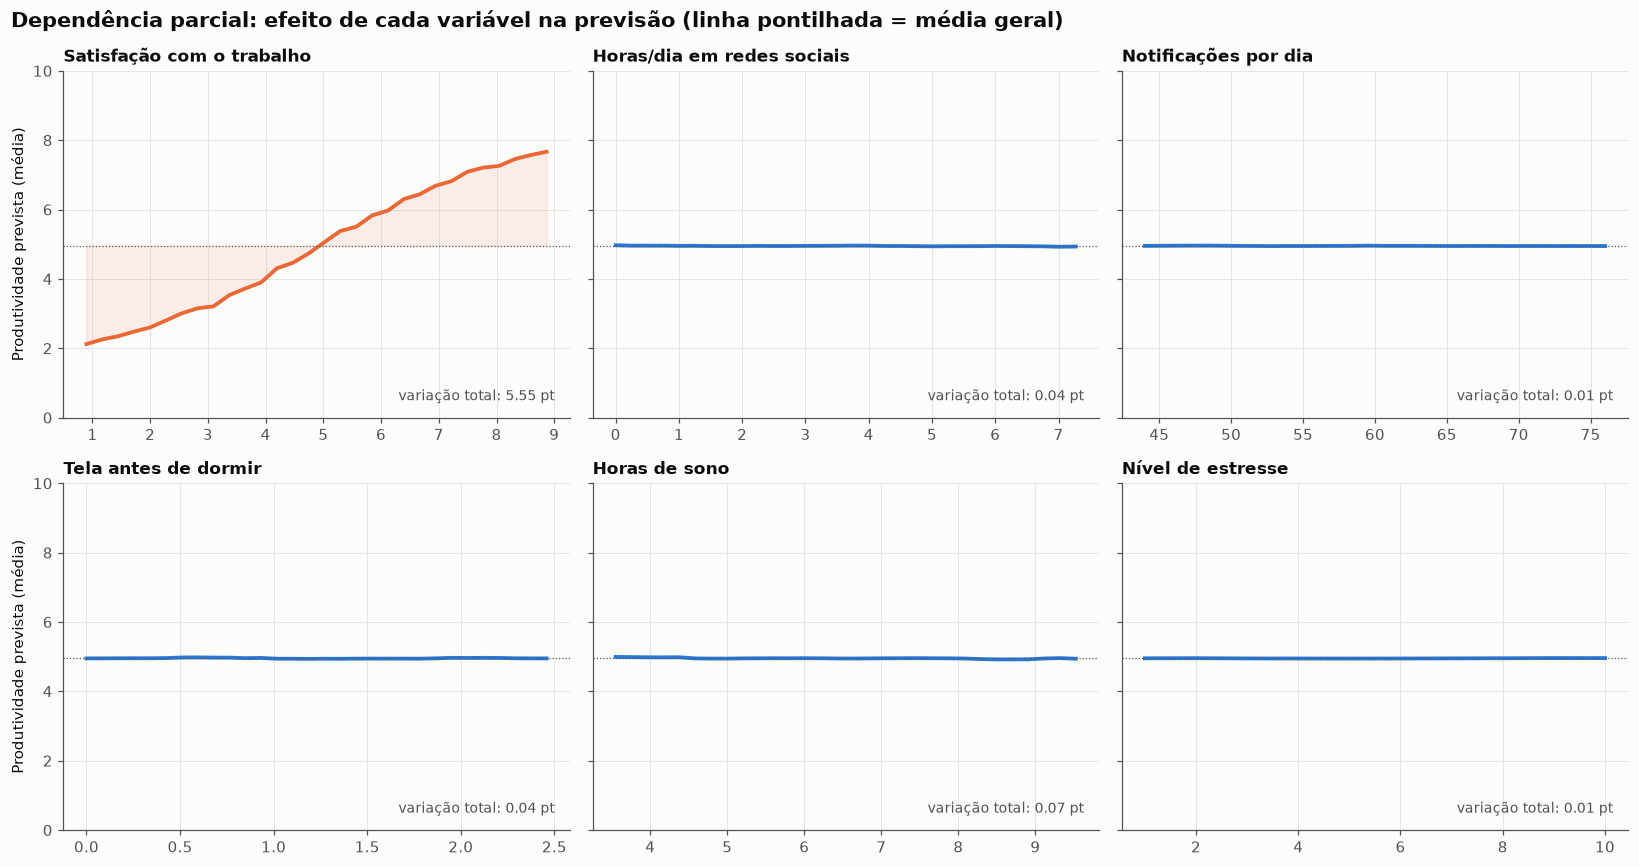

,variação da previsão (pontos)
Satisfação com o trabalho,5.545
Horas de sono,0.073
Horas/dia em redes sociais,0.044
Tela antes de dormir,0.043
Nível de estresse,0.014
Notificações por dia,0.013


In [10]:
pd_vars = ["job_satisfaction_score", "daily_social_media_time", "number_of_notifications",
           "screen_time_before_sleep", "sleep_hours", "stress_level"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
efeitos = {}
for ax, var in zip(axes.flat, pd_vars):
    res = partial_dependence(modelo, X_test, [var], grid_resolution=30, percentiles=(0.02, 0.98))
    grade, media = res["grid_values"][0], res["average"][0]
    efeitos[nome(var)] = media.max() - media.min()
    cor = ORANGE if var == "job_satisfaction_score" else BLUE
    ax.plot(grade, media, color=cor, lw=2.5)
    ax.fill_between(grade, media, y_test.mean(), color=cor, alpha=0.1)
    ax.axhline(y_test.mean(), color=INK_2, lw=0.8, ls=":")
    ax.set_ylim(0, 10)
    ax.set_title(nome(var), fontsize=11)
    ax.text(0.97, 0.05, f"variação total: {media.max() - media.min():.2f} pt", transform=ax.transAxes,
            ha="right", fontsize=9, color=INK_2)
for ax in axes[:, 0]:
    ax.set_ylabel("Produtividade prevista (média)")
fig.suptitle("Dependência parcial: efeito de cada variável na previsão (linha pontilhada = média geral)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
salvar(fig, "04_dependencia_parcial")
plt.show()

pd.Series(efeitos, name="variação da previsão (pontos)").sort_values(ascending=False).round(3).to_frame()

## 8. Simulação "e se?": reduzir as redes sociais ou aumentar a satisfação?

Pegamos as 5.527 pessoas do teste e perguntamos ao modelo:

- **Cenário A:** *e se todas reduzissem o uso de redes sociais para 1 h/dia e recebessem poucas notificações?*
- **Cenário B:** *e se todas passassem a usar o celular intensamente, com 8 h/dia e muitas notificações?*
- **Cenário C:** *e se a satisfação com o trabalho de todas aumentasse 2 pontos?*

Todo o resto de cada pessoa permanece igual.

In [11]:
pred_base = modelo.predict(X_test)
p5_notif, p95_notif = X_train["number_of_notifications"].quantile([0.05, 0.95])

cenarios = {
    "A: 1 h/dia de redes + poucas notificações": X_test.assign(
        daily_social_media_time=1.0, number_of_notifications=p5_notif, screen_time_before_sleep=0.0),
    "B: 8 h/dia de redes + muitas notificações": X_test.assign(
        daily_social_media_time=8.0, number_of_notifications=p95_notif, screen_time_before_sleep=2.5),
    "C: +2 pontos de satisfação no trabalho": X_test.assign(
        job_satisfaction_score=(X_test["job_satisfaction_score"] + 2).clip(upper=10)),
}

simulacao = []
for nome_cenario, X_cen in cenarios.items():
    delta = modelo.predict(X_cen) - pred_base
    simulacao.append({
        "cenário": nome_cenario,
        "mudança média (pontos)": delta.mean(),
        "% com mudança > 0,5 pt": (np.abs(delta) > 0.5).mean() * 100,
    })
simulacao = pd.DataFrame(simulacao).set_index("cenário")
simulacao.round(3)

,mudança média (pontos),"% com mudança > 0,5 pt"
cenário,,
A: 1 h/dia de redes + poucas notificações,-0.000,0.036
B: 8 h/dia de redes + muitas notificações,-0.025,0.018
C: +2 pontos de satisfação no trabalho,1.423,96.038


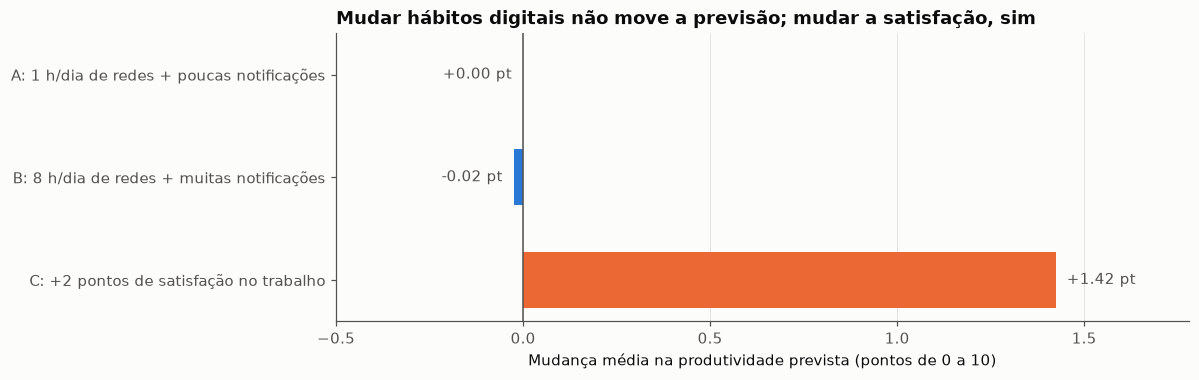

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.4))
d = simulacao["mudança média (pontos)"][::-1]
cores = [ORANGE if v > 0.5 else BLUE for v in d.values]
ax.barh(d.index, d.values, color=cores, height=0.55)
ax.axvline(0, color=INK_2, lw=1)
for i, v in enumerate(d.values):
    v_txt = 0.0 if abs(v) < 0.005 else v
    ax.text(v + (0.03 if v >= 0 else -0.03), i, f"{v_txt:+.2f} pt", va="center",
            ha="left" if v >= 0 else "right", fontsize=10, color=INK_2)
ax.set_xlim(-0.5, max(d.max() * 1.25, 0.5))
ax.set_xlabel("Mudança média na produtividade prevista (pontos de 0 a 10)")
ax.set_title("Mudar hábitos digitais não move a previsão; mudar a satisfação, sim")
ax.grid(axis="y", visible=False)
salvar(fig, "04_simulacao_cenarios")
plt.show()

## 9. Rede social favorita importa?

In [13]:
plataformas = [c for c in FEATURES if c.startswith("platform_")]
por_rede = {}
for p in plataformas:
    X_p = X_test.copy()
    X_p[plataformas] = 0.0
    X_p[p] = 1.0
    por_rede[p.removeprefix("platform_")] = modelo.predict(X_p).mean()
por_rede = pd.Series(por_rede, name="produtividade prevista média").sort_values()
print(f"Diferença entre a 'melhor' e a 'pior' rede: {por_rede.max() - por_rede.min():.3f} ponto")
por_rede.round(3).to_frame()

Diferença entre a 'melhor' e a 'pior' rede: 0.019 ponto


,produtividade prevista média
Telegram,4.928
TikTok,4.938
Instagram,4.942
Twitter,4.946
Facebook,4.947


Se **todas as pessoas do teste** usassem a mesma rede favorita, a previsão média mudaria menos de 0,02 ponto entre TikTok, Instagram, Facebook, Twitter e Telegram. Para o modelo, a rede preferida é irrelevante.

## 10. Salvando os resultados

In [14]:
importancias = pd.DataFrame({
    "nome": [nome(c) for c in FEATURES],
    "mdi": mdi[FEATURES].values,
    "permutacao": perm_df.loc[FEATURES, "queda_r2"].values,
    "permutacao_desvio": perm_df.loc[FEATURES, "desvio"].values,
}, index=pd.Index(FEATURES, name="feature")).sort_values("permutacao", ascending=False)
importancias.to_csv(MODEL_DIR / "feature_importance.csv")
print(f"Salvo em {MODEL_DIR / 'feature_importance.csv'}")
print(f"Figuras: {sorted(p.name for p in FIG_DIR.glob('04_*.png'))}")

Salvo em models/feature_importance.csv
Figuras: ['04_dependencia_parcial.png', '04_feature_importance_mdi.png', '04_feature_importance_permutacao.png', '04_importancia_por_tema.png', '04_mdi_vs_ruido.png', '04_simulacao_cenarios.png']


## 11. Análise: o que o algoritmo descobriu sobre redes sociais e produtividade

### 11.1 A resposta direta

**Neste dataset, os hábitos de uso de redes sociais não têm impacto mensurável na produtividade real.** Seis evidências independentes, todas apontando na mesma direção:

| Evidência | Resultado |
|---|---|
| Correlação (Fase 1) | \|r\| < 0,02 entre qualquer hábito digital e a produtividade |
| Informação mútua (Fase 1) | ~0, ou seja, também não há relação não linear |
| Importância por permutação | Embaralhar o tempo em redes sociais muda o R² em menos de 0,001 |
| Importância por tema | As 11 variáveis de hábitos digitais juntas valem ~0 de R² |
| Dependência parcial | Ir de 0 a 8 h/dia de redes sociais move a previsão em centésimos de ponto |
| Simulação | Forçar 8 h/dia e muitas notificações em todo mundo praticamente não muda a produtividade prevista |

### 11.2 O que realmente importa: satisfação com o trabalho

A satisfação com o trabalho concentra praticamente **toda** a capacidade preditiva do modelo. A dependência parcial mostra uma relação crescente e quase linear: quem está mais satisfeito é previsto como bem mais produtivo. No cenário C, aumentar em 2 pontos a satisfação de todas as pessoas eleva a produtividade prevista em mais de 1 ponto, um efeito **dezenas de vezes maior** que qualquer mudança de hábito digital.

### 11.3 O que o algoritmo fez bem

- **Seleção automática de variáveis:** o Random Forest recebeu 28 variáveis sem nenhuma indicação de qual era relevante e concentrou o uso na única com sinal.
- **Robustez ao ruído:** as outras 27 variáveis não prejudicaram o desempenho no teste. A floresta generalizou tão bem quanto um modelo que usa apenas a variável correta (Fase 3).
- **Interpretabilidade:** com permutação, dependência parcial e simulações, transformamos a "caixa-preta" em conclusões verificáveis.

### 11.4 Cuidados de interpretação (limitações)

1. **Dados sintéticos.** A Fase 1 mostrou que as variáveis são praticamente independentes entre si (ex.: mais tempo em redes sociais não está associado a menos sono ou mais estresse), algo improvável em dados reais de comportamento humano. O dataset parece ter sido **gerado artificialmente**, com a produtividade construída a partir da satisfação mais ruído. O modelo aprendeu corretamente as regras **deste** dataset, mas elas não necessariamente valem para o mundo real.
2. **Correlação não é causalidade.** Mesmo em dados reais, um Random Forest aprende associações. "Aumentar a satisfação aumenta a produtividade" é uma leitura da simulação do modelo, não um experimento controlado.
3. **A literatura real é mais nuançada.** Pesquisas com dados reais costumam encontrar efeitos negativos associados principalmente a **interrupções** (notificações, troca constante de tarefa) e ao **uso problemático ou compulsivo**, e não necessariamente ao tempo total de uso. Esses efeitos costumam ser modestos. A ausência total de efeito encontrada aqui é uma característica do dataset, não uma refutação dessas pesquisas.
4. **~28% da variação permanece inexplicada.** Nenhuma variável disponível explica essa parte, e é ela que faz o modelo "puxar" as previsões extremas para o centro (Fase 3).

### 11.5 Lições de Machine Learning para levar

1. **O modelo só aprende o que está nos dados.** Um algoritmo sofisticado não cria uma relação que não existe. Dados sintéticos geram conclusões sintéticas.
2. **Sempre compare com um baseline simples.** O Random Forest empatou com uma regressão linear de uma única variável, e essa comparação é o que revela que não havia padrões complexos para descobrir.
3. **Desconfie da Feature Importance nativa (MDI).** Ela deu ~1% de importância a variáveis que se comportam exatamente como números sorteados. A permutação no teste revela a verdade.
4. **Um resultado "nulo" é um resultado.** Descobrir que os hábitos digitais **não** preveem a produtividade, com evidência sólida, é tão informativo quanto descobrir que preveem.